# Genome Annotation Enhancement Pipeline — Annotated Copy

This is an annotated copy of `genomeAlignment.ipynb` (original left untouched). Markdown notes have been added above each step to explain what it does, and summary graphs of gene/protein counts through the pipeline have been appended at the end. No analysis logic was changed.

**Overall pipeline:** BRAKER-predicted gene isoforms → MMseqs2 alignment against four reference proteomes → best hit filtering (≥95% identity) → AlphaFold structure lookup for matched proteins → classification into Characterized / Uncharacterized / Not Found → best cross-strain annotation per isoform.

## Step 1 — Load MMseqs2 alignment results
Reads the pairwise MMseqs2 alignment output (query = our BRAKER-predicted isoforms, target = proteins in each reference proteome) for four comparison strains/species: *R. oligosporus*, ATCC 11559, ATCC 52813, and *R. delemar*.

In [1]:
import pandas as pd

header = ["query", "target", "fident", "alnlen", "mismatch", "gapopen", "qstart", "qend", "tstart", "tend", "evalue", "bits"]
RoligoAlignment = pd.read_csv("RmicroRoligo.tsv", sep="\t", names=header)
ATCC52813Alignment = pd.read_csv("TomVS52813.tsv", sep="\t", names=header)
ATCC11559Alignment = pd.read_csv("TomVSCarlos.tsv", sep="\t", names=header)
RdelemarAlignment = pd.read_csv("RmicroRdele.tsv", sep='\t', names=header)

## Step 2 — Keep the single best hit per query, above an identity cutoff
For each query isoform, keep only its highest-identity (`fident`) hit against each reference proteome, then discard hits below `cutoff = 0.95` sequence identity. This defines, per strain, which of our predicted isoforms have a confident match to an already-annotated protein.

In [2]:
df_list = [RoligoAlignment, ATCC11559Alignment, ATCC52813Alignment, RdelemarAlignment]

cutoff = 0.95

ATCC52813Filtered = ATCC52813Alignment.loc[ATCC52813Alignment.groupby('query')['fident'].idxmax()]
ATCC52813Filtered = ATCC52813Filtered[ATCC52813Filtered['fident']>cutoff].reset_index(drop=True)

ATCC11559Filtered = ATCC11559Alignment.loc[ATCC11559Alignment.groupby('query')['fident'].idxmax()]
ATCC11559Filtered = ATCC11559Filtered[ATCC11559Filtered['fident']>cutoff].reset_index(drop=True)

RoligoFiltered = RoligoAlignment.loc[RoligoAlignment.groupby('query')['fident'].idxmax()]
RoligoFiltered = RoligoFiltered[RoligoFiltered['fident']>cutoff].reset_index(drop=True)

RdelemarFiltered = RdelemarAlignment.loc[RdelemarAlignment.groupby('query')['fident'].idxmax()]
RdelemarFiltered = RdelemarFiltered[RdelemarFiltered['fident']>cutoff].reset_index(drop=True)

## Step 3 — Load the full BRAKER gene set
`braker_metadata.xlsx` lists every gene/isoform predicted by BRAKER for our genome — this is the starting universe of proteins that everything downstream is measured against.

In [3]:
braker = pd.read_excel('braker_metadata.xlsx')
isoforms = braker['SequenceID'].tolist()
not52813 = set(isoforms) - set(ATCC52813Filtered['query'])
not11559 = set(isoforms) - set(ATCC11559Filtered['query'])
notRoligo = set(isoforms) - set(RoligoFiltered['query'])
notRdelemar = set(isoforms) - set(RdelemarFiltered['query'])



## Step 4 — Count isoforms with *no* confident match in each reference
`notX` = BRAKER isoforms that did **not** clear the 0.95 identity cutoff against strain X. The complement (matched = total − missing) is how many isoforms *were* successfully cross-annotated from that reference proteome.

In [4]:
Amount_of_missing = [len(not52813), len(not11559), len(notRoligo), len(notRdelemar)]
print(Amount_of_missing)

[20714, 17994, 15431, 26422]


## Step 5 — UniProt lookup helper
Defines a batched UniProt REST query used later to check organism/accession metadata for matched target IDs (not run further downstream in this notebook).

In [5]:
import requests
from time import sleep

def check_uniprot_ids_batch(protein_ids, organism_taxid=None):
    import io
    url = "https://rest.uniprot.org/uniprotkb/search"
    all_found = []

    chunk_size = 100
    for i in range(0, len(protein_ids), chunk_size):
        chunk = protein_ids[i:i+chunk_size]
        ids_query = " OR ".join([f"accession:{pid}" for pid in chunk])
        params = {
            "query": ids_query,
            "fields": "accession,organism_name,organism_id",
            "format": "tsv",
            "size": len(protein_ids)
        }

        response = requests.get(url, params=params)
        
        # Debug: print response
        print(f"Status: {response.status_code}, Response preview: {response.text[:200]}")
        
        if response.status_code != 200 or not response.text.strip():
            print(f"Skipping chunk {i} — bad response")
            continue

        chunk_df = pd.read_csv(io.StringIO(response.text), sep='\t')
        
        # Verify expected columns came back
        print(f"Columns returned: {chunk_df.columns.tolist()}")
        
        if len(chunk_df.columns) == 3:
            chunk_df.columns = ['protein_id', 'organism', 'taxid']
            all_found.append(chunk_df)

    if all_found:
        found_df = pd.concat(all_found, ignore_index=True)
    else:
        found_df = pd.DataFrame(columns=['protein_id', 'organism', 'taxid'])

    found_ids = set(found_df['protein_id']) if not found_df.empty else set()
    missing = [pid for pid in protein_ids if pid not in found_ids]

    if organism_taxid and not found_df.empty:
        found_df['status'] = found_df['taxid'].apply(
            lambda x: 'found' if x == organism_taxid else 'wrong_organism'
        )
    elif not found_df.empty:
        found_df['status'] = 'found'

    missing_df = pd.DataFrame({
        'protein_id': missing,
        'organism': None,
        'taxid': None,
        'status': 'not_found'
    })

    return pd.concat([found_df, missing_df], ignore_index=True)

## Step 6 — Collect the matched UniProt target IDs
Pulls the unique UniProt accessions (`target`) that our isoforms matched to in ATCC 52813 and ATCC 11559 — these are the IDs checked against AlphaFold in the next step.

In [6]:
ATCC52813IDS = ATCC52813Filtered['target'].unique().tolist()
ATCC11559IDS = ATCC11559Filtered['target'].unique().tolist()
#check_uniprot_ids_batch(ATCC52813IDS, 1340429)

## Step 7 — AlphaFold structure lookup
For every matched UniProt ID, queries the AlphaFold API to see whether a predicted structure exists (`found` / `not_found`) and pulls the UniProt description associated with that structure entry.

In [7]:
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

def check_alphafold_structures(protein_ids, max_workers=20):
    
    def fetch_single(pid):
        url = f"https://alphafold.ebi.ac.uk/api/prediction/{pid}"
        try:
            response = requests.get(url, timeout=10)
            if response.status_code == 200:
                data = response.json()
                entry = data[0] if data else {}
                return {
                    'protein_id': pid,
                    'alphafold_status': 'found',
                    'uniprot_description': entry.get('uniprotDescription', None),
                    'alphafold_id': entry.get('entryId', None),
                    'pdb_url': entry.get('pdbUrl', None)
                }
            elif response.status_code == 404:
                return {'protein_id': pid, 'alphafold_status': 'not_found', 'uniprot_description': None, 'alphafold_id': None, 'pdb_url': None}
            else:
                return {'protein_id': pid, 'alphafold_status': f'error_{response.status_code}', 'uniprot_description': None, 'alphafold_id': None, 'pdb_url': None}
        except Exception as e:
            return {'protein_id': pid, 'alphafold_status': f'error: {e}', 'uniprot_description': None, 'alphafold_id': None, 'pdb_url': None}

    results = []
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = {executor.submit(fetch_single, pid): pid for pid in protein_ids}
        for future in tqdm(as_completed(futures), total=len(protein_ids), desc="Checking AlphaFold", unit="protein"):
            results.append(future.result())

    return pd.DataFrame(results)

## Step 8 — Run the AlphaFold check (expensive, cached)
This cell actually calls `check_alphafold_structures` for both strains. It's commented out here because it takes several minutes — results were already computed once and saved to CSV (loaded in the next cell).

In [8]:
#do not run this cell. It will take a couple minutes.

#ATCC52813Results = check_alphafold_structures(ATCC52813IDS, max_workers=20)
#ATCC11559Results = check_alphafold_structures(ATCC11559IDS, max_workers=20)


## Step 9 — Load cached AlphaFold results
Reloads the previously saved per-protein AlphaFold status/description tables instead of re-querying the API.

In [9]:
#ATCC52813Results.to_csv("ATCC52813Results.csv", index=False)
#ATCC11559Results.to_csv("ATCC11559Results.csv", index=False)

ATCC52813Results = pd.read_csv('ATCC52813Results.csv')
ATCC11559Results = pd.read_csv('ATCC11559Results.csv')

## Step 10 — Classify matched proteins: Characterized vs. Uncharacterized vs. Not Found
Splits each strain's matched proteins into three buckets based on the AlphaFold/UniProt result: has a structure with a real description (**Characterized**), has a structure but is annotated only as `"Uncharacterized protein"` (**Uncharacterized**), or has no AlphaFold entry at all (**Not Found**).

In [10]:
Uncharacterized52813 = ATCC52813Results[ATCC52813Results['uniprot_description'] == 'Uncharacterized protein']
Uncharacterized11559 = ATCC11559Results[ATCC11559Results['uniprot_description'] == 'Uncharacterized protein']

notFound52813 = ATCC52813Results[ATCC52813Results['alphafold_status'] == 'not_found']
notFound11559 = ATCC11559Results[ATCC11559Results['alphafold_status'] == 'not_found']

Characterized52813 = ATCC52813Results[(ATCC52813Results['alphafold_status'] == 'found') & (ATCC52813Results['uniprot_description'] != 'Uncharcterized Protein')]
Characterized11559 = ATCC11559Results[(ATCC11559Results['alphafold_status'] == 'found') & (ATCC11559Results['uniprot_description'] != 'Uncharcterized Protein')]

## Step 11 — Save the classified sets to CSV
Persists the Characterized / Uncharacterized / Not-Found tables for each strain.

In [11]:
Uncharacterized11559.to_csv("ATCC11559Unchar.csv", index=False)
Uncharacterized52813.to_csv("ATCC52813Unchar.csv", index=False)
notFound11559.to_csv("ATCC11559NotFound.csv", index=False)
notFound52813.to_csv("ATCC52813NotFound.csv", index=False)
Characterized11559.to_csv("ATCC11559Char.csv", index=False)
Characterized52813.to_csv("ATCC52813Char.csv", index=False)


## Step 12 — Compare characterized sets between strains, prep for merging
Counts characterized proteins unique to ATCC 11559 vs. ATCC 52813, and reindexes both results tables by `protein_id` for fast lookup in the isoform-mapping step below.

In [12]:
print(len(set(Characterized11559['protein_id'])-set(Characterized52813['protein_id'])))

ATCC11559Results = ATCC11559Results.set_index('protein_id')
ATCC52813Results = ATCC52813Results.set_index('protein_id')

9250


## Step 13 — Build a per-isoform annotation map for each strain
For every query isoform, look up its best target's AlphaFold status and description in each strain, producing `isoform_map[query] = [strain1_entry, strain2_entry]`.

In [13]:
def build_isoform_map(filtered_df, results_df):
    """
    Build entries for one strain.
    
    filtered_df : e.g. ATCC11559Filtered  — columns: 'query', 'target', 'fident'
    results_df  : e.g. ATCC11559Results   — indexed by uniprot_id, 
                                            columns: 'alphafold_status', 'uniprot_description'
    """
    entries = {}
    for _, row in filtered_df[['query', 'target', 'fident']].iterrows():
        uniprot_id = row['target']
        
        # Look up metadata from Results df using uniprot_id as index
        if uniprot_id in results_df.index:
            alphafold_status    = results_df.loc[uniprot_id, 'alphafold_status']
            uniprot_description = results_df.loc[uniprot_id, 'uniprot_description']
        else:
            alphafold_status    = None
            uniprot_description = None
        
        entries[row['query']] = [
            uniprot_id,
            row['fident'],
            alphafold_status,
            uniprot_description
        ]
    
    return entries

# Build per-strain entries
strain1_entries = build_isoform_map(ATCC11559Filtered, ATCC11559Results)
strain2_entries = build_isoform_map(ATCC52813Filtered, ATCC52813Results)

# Merge: key = query isoform, value = [strain1_list, strain2_list]
all_queries = set(strain1_entries) | set(strain2_entries)

isoform_map = {
    query: [
        strain1_entries.get(query),  # None if isoform absent in strain 1
        strain2_entries.get(query)   # None if isoform absent in strain 2
    ]
    for query in all_queries
}

Example lookup — one isoform's annotation from both strains.

In [14]:
print(isoform_map['g23870.t1'])

[['A0A1X0S310', 0.973, 'found', 'Serine/threonine-protein kinase pef1'], ['A0A2G4SZ12', 0.976, 'found', 'cyclin-dependent kinase']]


## Step 14 — Pick the best strain match per isoform
Where an isoform matched in both strains, keep whichever hit has the higher identity (`fident`); where it only matched in one, keep that one. This collapses the two per-strain maps into a single best annotation per isoform (`best_isoform_map`).

In [15]:
def get_best_strain(strain1_entry, strain2_entry):
    """
    Compare fident (index 1) between two strain entries and return
    the best one along with a strain label.
    Returns: [uniprot_id, fident, alphafold_status, uniprot_description, strain]
    """
    if strain1_entry is None and strain2_entry is None:
        return None
    if strain1_entry is None:
        return strain2_entry + ['ATCC52813']
    if strain2_entry is None:
        return strain1_entry + ['ATCC11559']

    # Both present — pick higher fident
    if strain1_entry[1] >= strain2_entry[1]:
        return strain1_entry + ['ATCC11559']
    else:
        return strain2_entry + ['ATCC52813']


best_isoform_map = {
    query: get_best_strain(entries[0], entries[1])
    for query, entries in isoform_map.items()
}

Example — the resolved best-strain annotation for the same isoform.

In [16]:
print(best_isoform_map['g23870.t1'])

['A0A2G4SZ12', 0.976, 'found', 'cyclin-dependent kinase', 'ATCC52813']


## Step 15 — Final tally: how many BRAKER isoforms got annotated at all?
Checks every isoform in the original BRAKER gene set against `best_isoform_map` to see how many ended up with **any** cross-strain annotation versus how many remained completely unmatched.

In [17]:
missing_key = []
existing_key = []
for protein in isoforms:
    if protein not in best_isoform_map:
        missing_key.append(protein)
    else:
        existing_key.append(protein)

print(f"{len(existing_key)} isoforms mapped, {len(missing_key)} missing")

10648 isoforms mapped, 16570 missing


Sanity check — size of the ATCC 52813 "not found in AlphaFold" table.

In [18]:
notFound52813.shape

(195, 5)

## Step 16 — Export the final ATCC 52813 isoform dictionary
Builds a lookup of each characterized ATCC 52813 UniProt protein back to its originating query isoform (best/first alignment hit) and writes it to `52813_dictionary.csv` — this file is consumed downstream by the promoter-panel notebooks to restrict candidate genes to ones with confirmed structural/functional annotation.

In [19]:
best_matches = (
    ATCC52813Alignment
    .sort_values('fident', ascending=False)
    .drop_duplicates(subset='target', keep='first')
)

merge = Characterized52813.merge(
    best_matches[['target', 'query']],
    left_on='protein_id',
    right_on='target',
    how='left'
).drop(columns=['target'])

merge.to_csv("52813_dictionary.csv", index=False)

---
# Summary graphs: gene/protein counts through the pipeline

The cells below reuse variables already computed above (no recomputation of alignments or API calls) and just visualize how many genes/proteins survive each stage.

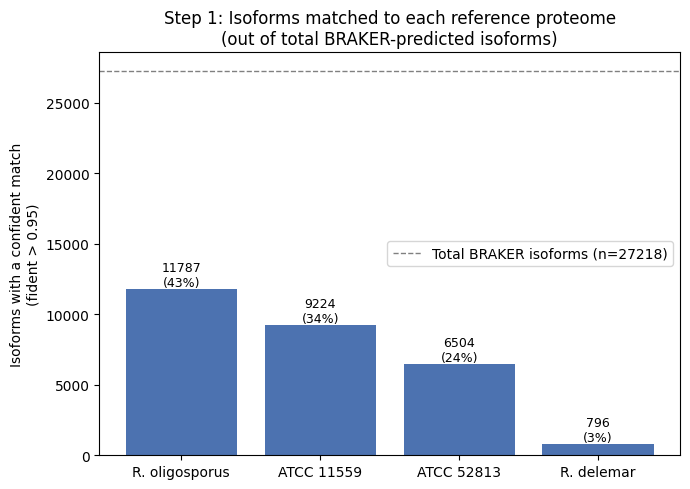

In [20]:
import matplotlib.pyplot as plt
import numpy as np

total_isoforms = len(isoforms)
strain_names = ['R. oligosporus', 'ATCC 11559', 'ATCC 52813', 'R. delemar']
matched_counts = [
    total_isoforms - len(notRoligo),
    total_isoforms - len(not11559),
    total_isoforms - len(not52813),
    total_isoforms - len(notRdelemar),
]

fig, ax = plt.subplots(figsize=(7,5))
bars = ax.bar(strain_names, matched_counts, color='#4C72B0')
ax.axhline(total_isoforms, color='gray', linestyle='--', linewidth=1, label=f'Total BRAKER isoforms (n={total_isoforms})')
for b, v in zip(bars, matched_counts):
    ax.text(b.get_x()+b.get_width()/2, v+200, f'{v}\n({v/total_isoforms:.0%})', ha='center', fontsize=9)
ax.set_ylabel('Isoforms with a confident match\n(fident > 0.95)')
ax.set_title('Step 1: Isoforms matched to each reference proteome\n(out of total BRAKER-predicted isoforms)')
ax.legend()
plt.tight_layout()
plt.savefig('genes_matched_per_strain.png', dpi=150)
plt.show()

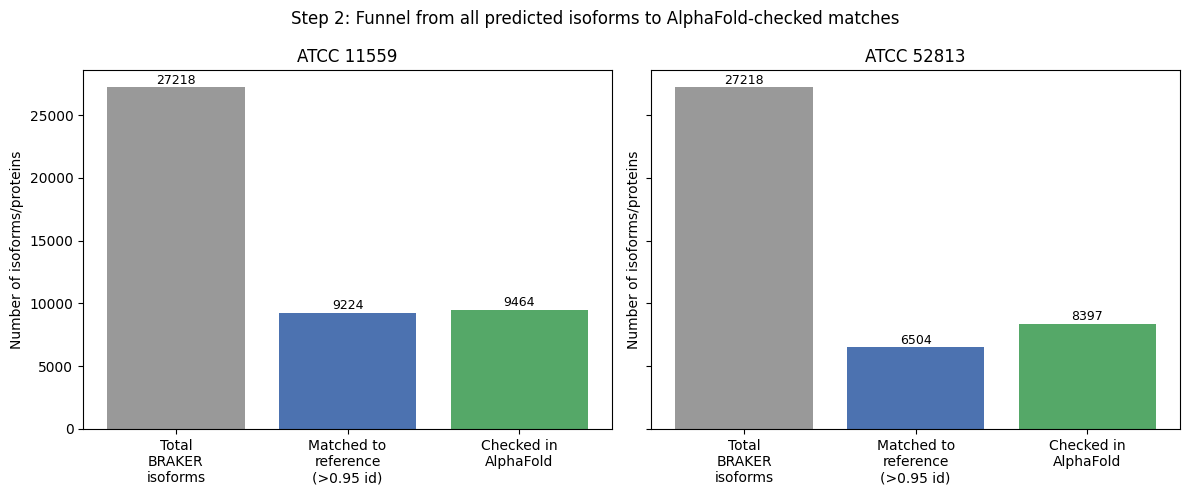

In [21]:
# Funnel for the two focal strains: total -> matched -> checked in AlphaFold -> classified
fig, axes = plt.subplots(1, 2, figsize=(12,5), sharey=True)

funnel_data = {
    'ATCC 11559': [total_isoforms, len(ATCC11559Filtered), len(ATCC11559Results),
                    len(Characterized11559), len(Uncharacterized11559), len(notFound11559)],
    'ATCC 52813': [total_isoforms, len(ATCC52813Filtered), len(ATCC52813Results),
                    len(Characterized52813), len(Uncharacterized52813), len(notFound52813)],
}

for ax, (strain, vals) in zip(axes, funnel_data.items()):
    total, matched, checked, char, unchar, nf = vals
    stages = ['Total\nBRAKER\nisoforms', 'Matched to\nreference\n(>0.95 id)', 'Checked in\nAlphaFold']
    counts = [total, matched, checked]
    bars = ax.bar(stages, counts, color=['#999999', '#4C72B0', '#55A868'])
    for b, v in zip(bars, counts):
        ax.text(b.get_x()+b.get_width()/2, v+300, f'{v}', ha='center', fontsize=9)
    ax.set_title(f'{strain}')
    ax.set_ylabel('Number of isoforms/proteins')

plt.suptitle('Step 2: Funnel from all predicted isoforms to AlphaFold-checked matches')
plt.tight_layout()
plt.savefig('funnel_total_to_alphafold_checked.png', dpi=150)
plt.show()

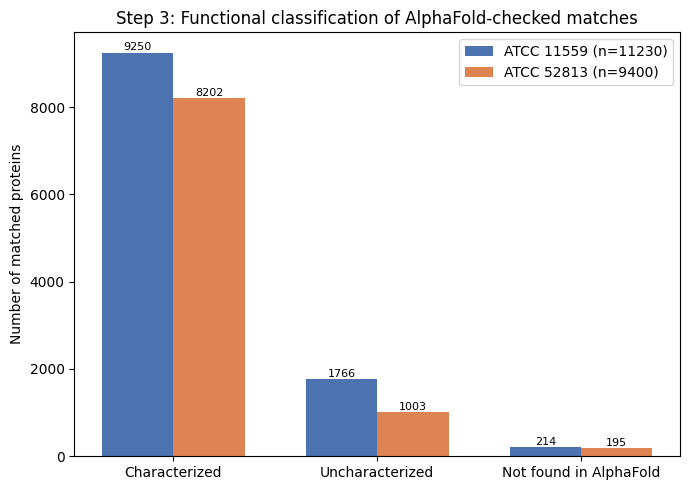

In [22]:
# Classification of matched, AlphaFold-checked proteins: Characterized / Uncharacterized / Not Found
fig, ax = plt.subplots(figsize=(7,5))

categories = ['Characterized', 'Uncharacterized', 'Not found in AlphaFold']
c11559 = [len(Characterized11559), len(Uncharacterized11559), len(notFound11559)]
c52813 = [len(Characterized52813), len(Uncharacterized52813), len(notFound52813)]

x = np.arange(len(categories))
width = 0.35
b1 = ax.bar(x - width/2, c11559, width, label=f'ATCC 11559 (n={sum(c11559)})', color='#4C72B0')
b2 = ax.bar(x + width/2, c52813, width, label=f'ATCC 52813 (n={sum(c52813)})', color='#DD8452')

for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+50, f'{int(b.get_height())}', ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylabel('Number of matched proteins')
ax.set_title('Step 3: Functional classification of AlphaFold-checked matches')
ax.legend()
plt.tight_layout()
plt.savefig('classification_characterized_vs_uncharacterized.png', dpi=150)
plt.show()

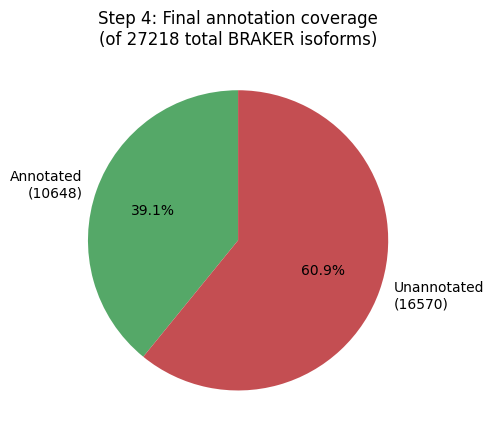

In [23]:
# Final tally: fraction of all BRAKER isoforms that ended up with any cross-strain annotation
fig, ax = plt.subplots(figsize=(5,5))
labels = [f'Annotated\n({len(existing_key)})', f'Unannotated\n({len(missing_key)})']
sizes = [len(existing_key), len(missing_key)]
ax.pie(sizes, labels=labels, autopct='%1.1f%%', colors=['#55A868', '#C44E52'], startangle=90)
ax.set_title(f'Step 4: Final annotation coverage\n(of {len(isoforms)} total BRAKER isoforms)')
plt.tight_layout()
plt.savefig('final_annotation_coverage.png', dpi=150)
plt.show()